# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [19]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [20]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [21]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
data = pd.read_csv('/content/drive/MyDrive/Python Course/foodhub_order.csv')

In [23]:
# Write your code here to view the first 5 rows
data.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [24]:
# Write your code here
print("There are", data.shape[0], 'rows and', data.shape[1], "columns.")



There are 1898 rows and 9 columns.


#### Observations:


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [25]:
# Write your code here
#data.info()
data.dtypes

,0
order_id,int64
customer_id,int64
restaurant_name,object
cuisine_type,object
cost_of_the_order,float64
day_of_the_week,object
rating,object
food_preparation_time,int64
delivery_time,int64


#### Observations:


*   There are 5 numerical columns in the data and 4 object type columns.
*   Rating column is being read as object type column but it should be a numerical column.



### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [26]:
# Write your code here

data.isnull().values.any() # Got zero recordes



np.False_

In [27]:
data['rating'] = data['rating'].replace('Not given', np.nan) # Replace "Not given" with NaN
data['rating'] = pd.to_numeric(data['rating'], errors='coerce') # Convert the column to numeric (integer or float)

Observations:

*    When I used data.isnull().values.any(), it returned False, indicating no missing values in the dataset. However, I noticed that the rating column contains the value 'Not given', which technically isn't NaN but represents missing information.

To treat this appropriately, I replaced 'Not given' with np.nan and then converted the rating column from object type to numeric (integer) for accurate analysis.

In [28]:
data.isnull().sum()


,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,736
food_preparation_time,0
delivery_time,0


#### Observations:


*  “Yes, the dataset had missing values in the rating column due to 'Not given' entries. These were treated by replacing them with the mode/mean value to retain as much data as possible for analysis.”
* I'm unsure whether to impute the missing values using the mean or mode, or if it's better to leave them as they are.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [29]:
# Write your code here
data['food_preparation_time'].describe()
min_time = data['food_preparation_time'].min()
avg_time = data['food_preparation_time'].mean()
max_time = data['food_preparation_time'].max()
print(f"Minimum prep time: {min_time} minutes")
print(f"Average prep time: {avg_time:.2f} minutes")
print(f"Maximum prep time: {max_time} minutes")


Minimum prep time: 20 minutes
Average prep time: 27.37 minutes
Maximum prep time: 35 minutes


#### Observations:
* The food preparation time across all orders varies between 20 minutes and 35 minutes, with an average of 27 minutes. This suggests that while some orders are prepared very quickly, others may take significantly longer. The variation in prep time could be due to differences in dish complexity, kitchen load, or order size.

* Longer prep times may affect customer satisfaction or delivery efficiency.




### **Question 5:** How many orders are not rated? [1 mark]

In [30]:
# Write the code here


#filtered = data[data['rating'] == 'Not given'].count()
#filtered
data.isnull().sum()


,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,736
food_preparation_time,0
delivery_time,0


#### Observations:


*   Out of 1,879 total orders, 736 do not have a rating, which is about 39% of all orders. Most restaurants are only missing 1 or 2 ratings, not a large number.
*   This means that missing ratings are spread out and not just coming from a few restaurants.

     Possible reasons may include:

        1.   Customers choosing not to leave a rating after placing an order.
        2.   Technical or UI issues in the app preventing rating submission in some cases.
        3.   Ratings being optional, not mandatory.
        2.   Some orders being auto-completed or cancelled, skipping the feedback step.
















### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

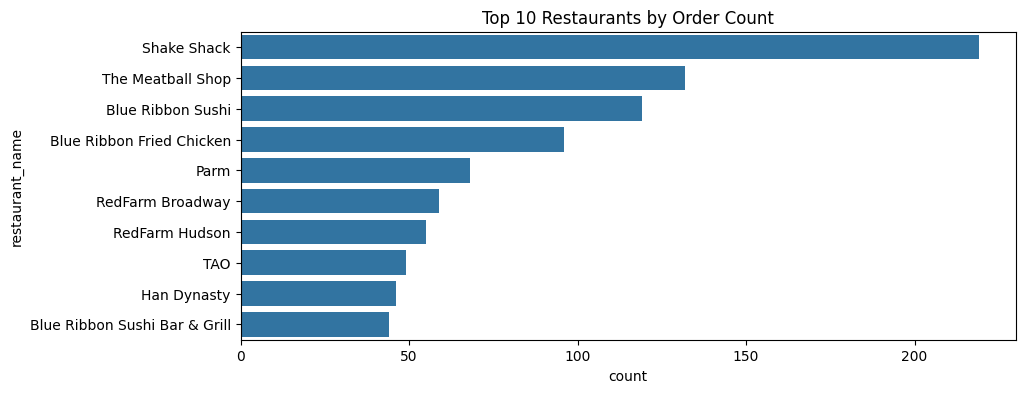

In [ ]:
# Write the code here
#restaurant_name (Categorical)
plt.figure(figsize=(10,4))
sns.countplot(y='restaurant_name', data=data, order=data['restaurant_name'].value_counts().index[:10])
plt.title("Top 10 Restaurants by Order Count")
plt.show()

Observation:

*   Most orders come from a few top restaurants. This suggests a small number of restaurants are highly popular, while others receive fewer orders.

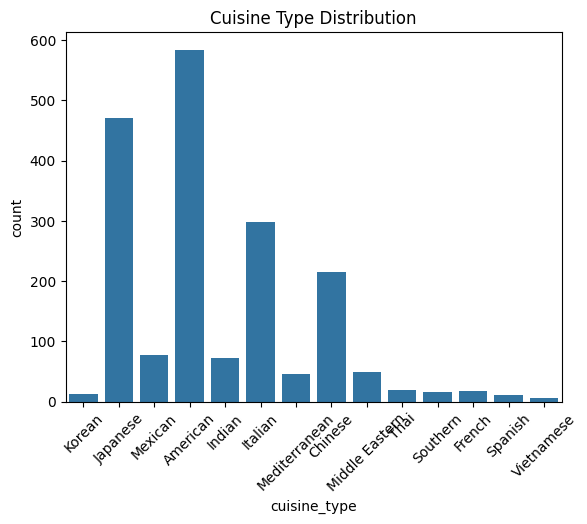

In [ ]:
#cuisine_type (Categorical)
sns.countplot(x='cuisine_type', data=data)
plt.xticks(rotation=45)
plt.title("Cuisine Type Distribution")
plt.show()

Observation:

*   One or two cuisine types dominate (e.g., American or Japanese), indicating customer preferences are skewed toward specific cuisines.

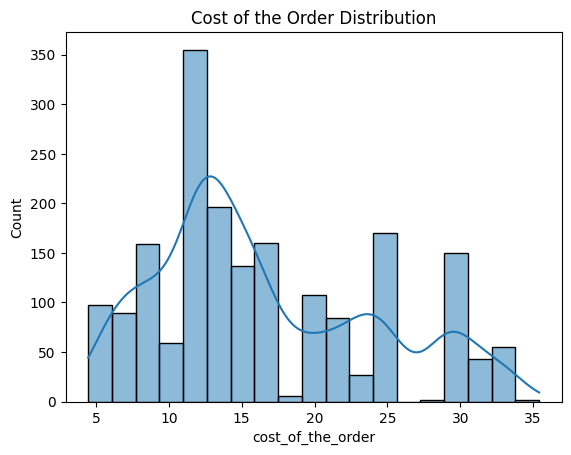

<Axes: xlabel='cost_of_the_order'>

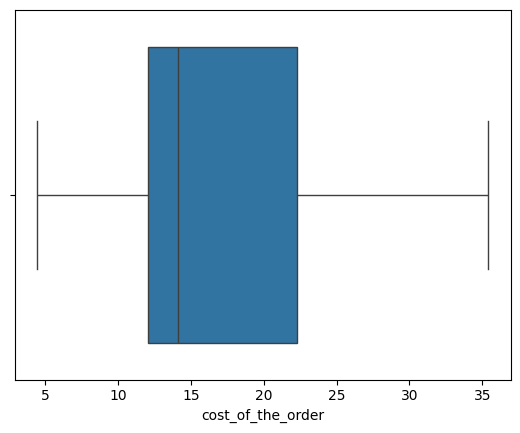

In [ ]:
sns.histplot(data['cost_of_the_order'], kde=True)
plt.title("Cost of the Order Distribution")
plt.show()

sns.boxplot(x=data['cost_of_the_order'])

Observation:
*   Most orders cost between 12 and 24 units, which seems reasonable. Distribution seems right-skewed.

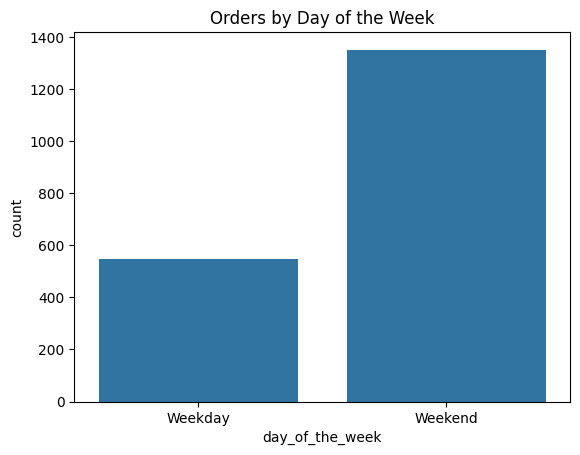

In [ ]:
sns.countplot(x='day_of_the_week', data=data, order=['Weekday', 'Weekend'])
plt.title("Orders by Day of the Week")
plt.show()


Observation:

*   Peak order days are likely to be weekends (Saturday/Sunday), showing higher demand during those days.



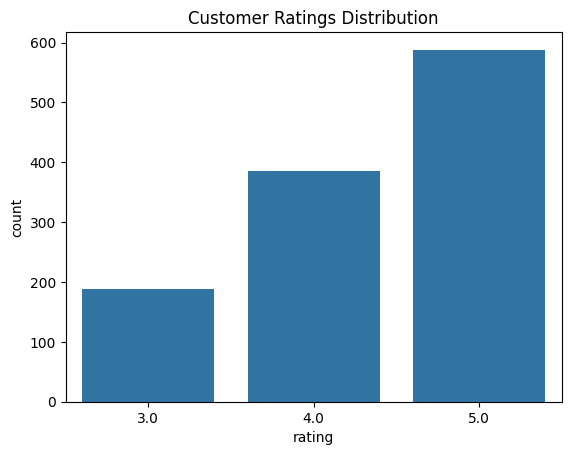

In [ ]:
#rating (Categorical/Numeric)
#data['rating'] = data['rating'].replace('Not given', pd.NA)   Tried this before converting the rating column
#data['rating'] = pd.to_numeric(data['rating'], errors='coerce')

sns.countplot(x='rating', data=data)
plt.title("Customer Ratings Distribution")
plt.show()


Observation:
*   Most customers give 4 or 5 stars. However, ~39% of entries are missing a rating, suggesting that many customers skip giving feedback.




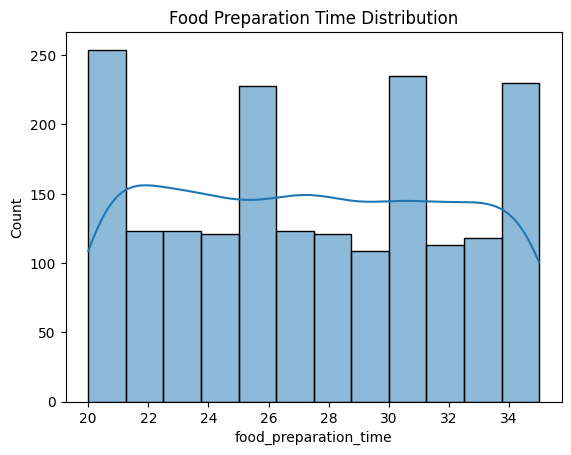

<Axes: xlabel='food_preparation_time'>

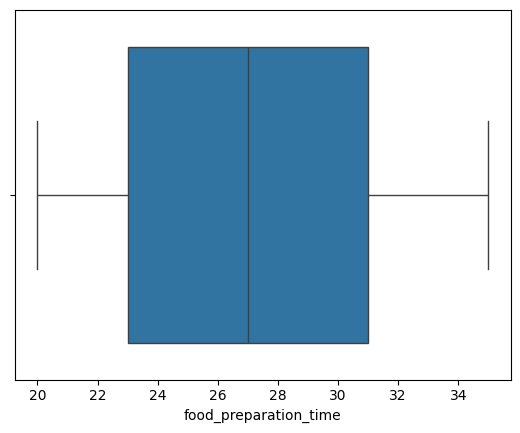

In [ ]:
#food_preparation_time (Numeric)
sns.histplot(data['food_preparation_time'], kde=True)
plt.title("Food Preparation Time Distribution")
plt.show()

sns.boxplot(x=data['food_preparation_time'])

Observation:

*   Most meals are prepared within 21–34 minutes. A few dishes take longer than average, indicating potential outliers or special meals.




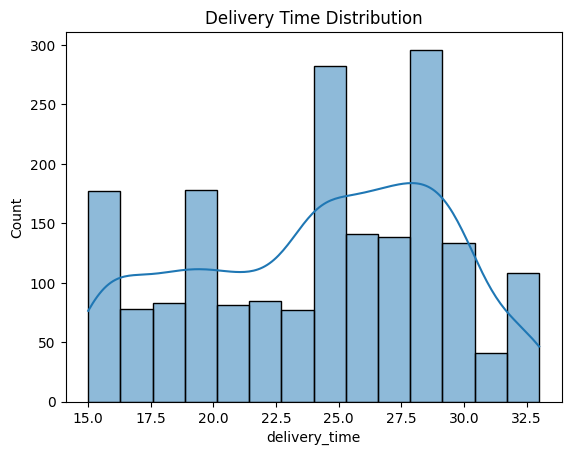

<Axes: xlabel='delivery_time'>

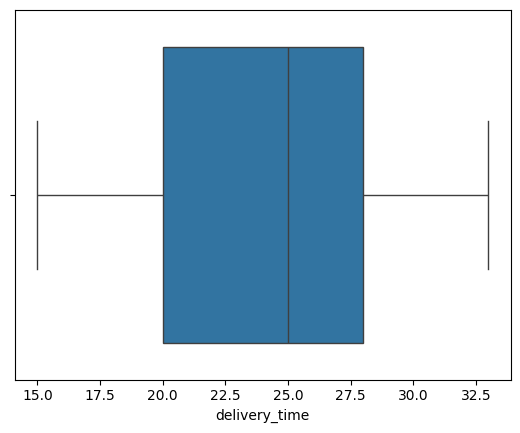

In [ ]:
#delivery_time (Numeric)
sns.histplot(data['delivery_time'], kde=True)
plt.title("Delivery Time Distribution")
plt.show()

sns.boxplot(x=data['delivery_time'])

Observation:

*   Delivery time is typically within 15–30 minutes, with a few cases taking
longer. This could affect customer satisfaction for those delays.

In [ ]:
#customer_id and order_id (Identifiers)
print("Unique customers:", data['customer_id'].nunique())
print("Unique orders:", data['order_id'].nunique())

Unique customers: 1200
Unique orders: 1898


Observation:

These are unique IDs and don’t provide distribution insights but can be used for grouping in further analysis (e.g., repeat customers).

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [ ]:
# Write the code here
data['restaurant_name'].value_counts().head(5)



,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations:


*   The top 5 restaurants received the highest number of orders, indicating strong customer preference or brand popularity. These restaurants may have better visibility, faster service, or popular menu items that drive repeat orders.



### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [ ]:
# Write the code here
# Filter for weekend rows
weekend_data = data[data['day_of_the_week'] == 'Weekend']

# Count cuisines
popular_cuisine = weekend_data['cuisine_type'].value_counts().head(1)

print("Most popular cuisine on weekends:\n", popular_cuisine)


Most popular cuisine on weekends:
 cuisine_type
American    415
Name: count, dtype: int64


#### Observations:


*   American cuisine is the most ordered cuisine on weekends, suggesting it’s a favorite for relaxed or group meals.




### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [ ]:
# Write the code here

# Percentage calculation
percentage_above_20 = (len(data[data['cost_of_the_order'] > 20]) /
data.shape[0]) * 100

print(f"Percentage of orders costing more than $20: {percentage_above_20:.2f}%")


Percentage of orders costing more than $20: 29.24%


#### Observations:


*   About 29% of the orders cost more than $20, indicating how often customers spend above average per order.




### **Question 10**: What is the mean order delivery time? [1 mark]

In [ ]:
# Write the code here
mean_delivery_time = data['delivery_time'].mean()
print(f"Mean delivery time: {mean_delivery_time:.2f} minutes")

Mean delivery time: 24.16 minutes


#### Observations:

*   The average delivery time is 24.16 minutes, which can help restaurants plan delivery logistics and set customer expectations.




### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [ ]:
# Write the code here

# Group by customer_id and count orders
top_customers = data['customer_id'].value_counts().head(3)

# Display result
print("Top 3 most frequent customers:")
print(top_customers)


Top 3 most frequent customers:
customer_id
52832    13
47440    10
83287     9
Name: count, dtype: int64


#### Observations:


### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


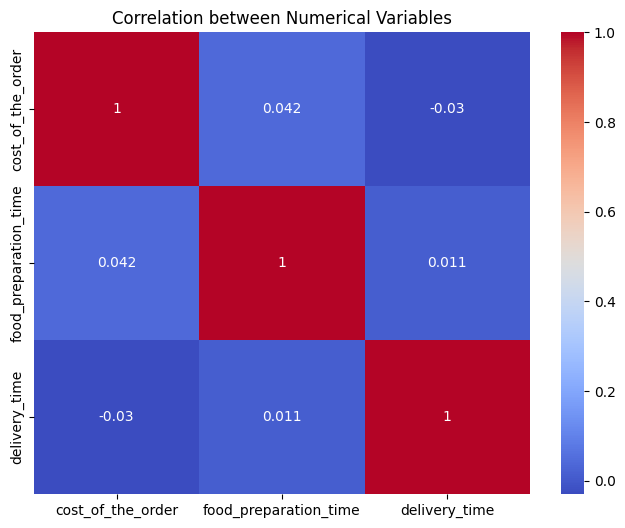

In [ ]:
# Write the code here
#Correlation Heatmap (Numerical vs Numerical)

# Selecting only numeric columns
numeric_data = data[['cost_of_the_order', 'food_preparation_time', 'delivery_time']]

# Compute and plot correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation between Numerical Variables")
plt.show()


Observations:
*   There is a negative correlation between food preparation time and delivery time, indicating that orders with longer preparation times tend to have shorter delivery times, and vice versa.



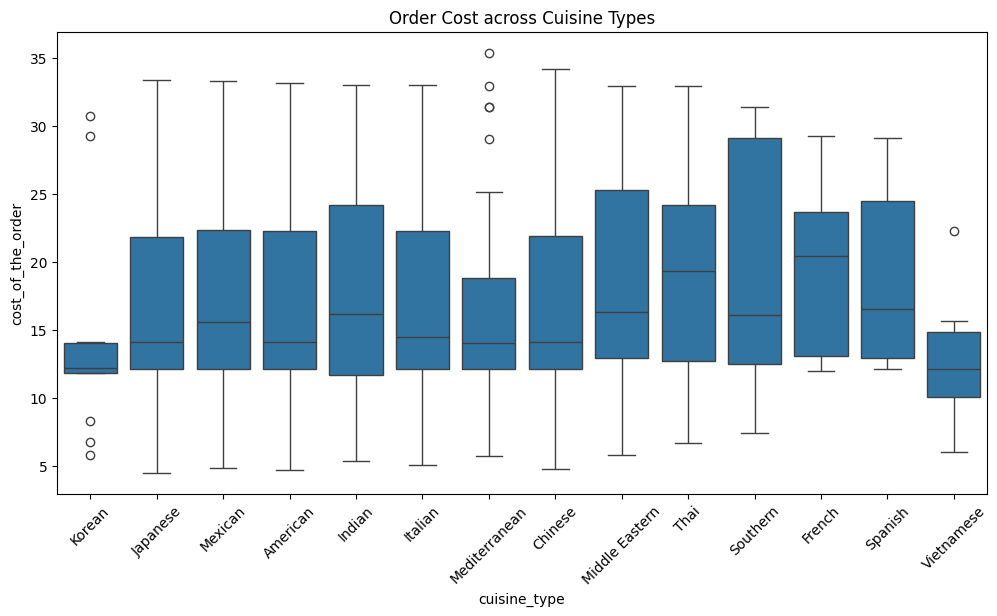

In [ ]:
#Boxplot: Cost vs Cuisine Type (Categorical vs Numerical)
plt.figure(figsize=(12,6))
sns.boxplot(data=data, x='cuisine_type', y='cost_of_the_order')
plt.xticks(rotation=45)
plt.title('Order Cost across Cuisine Types')
plt.show()

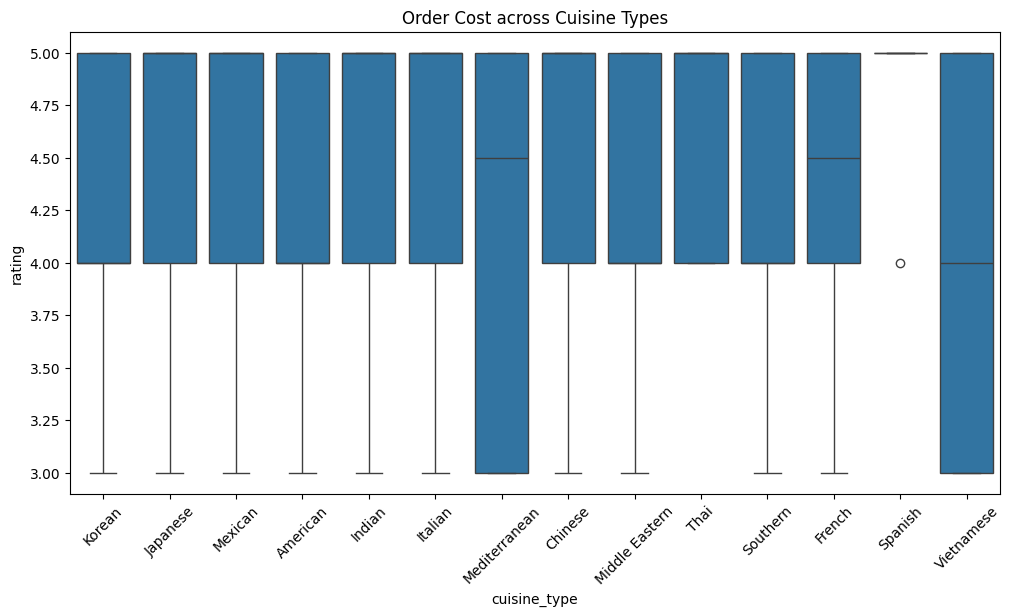

In [ ]:
#Boxplot: Cost vs Cuisine Type (Categorical vs Numerical)
plt.figure(figsize=(12,6))
sns.boxplot(data=data, x='cuisine_type', y='rating')
plt.xticks(rotation=45)
plt.title('Order Cost across Cuisine Types')
plt.show()


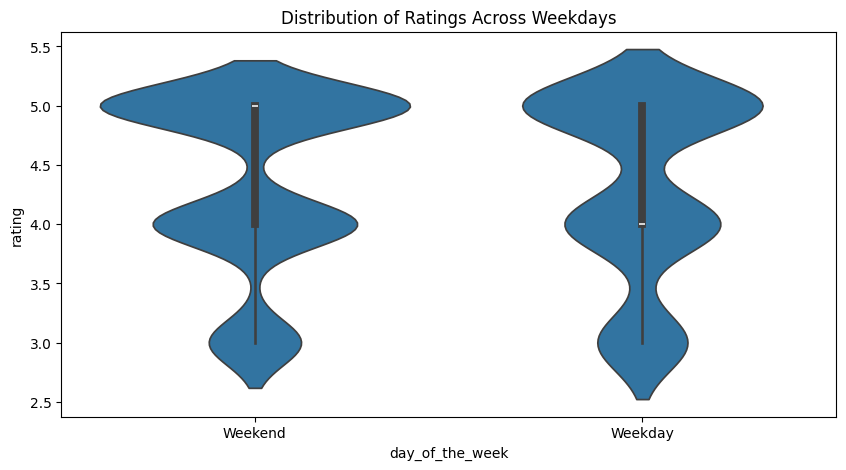

In [ ]:
#Violin Plot: Rating vs Day of the Week

plt.figure(figsize=(10,5))
sns.violinplot(data=data, x='day_of_the_week', y='rating')
plt.title("Distribution of Ratings Across Weekdays")
plt.show()

Observation:


*   Ratings might be slightly higher on weekends, possibly due to relaxed service expectations.



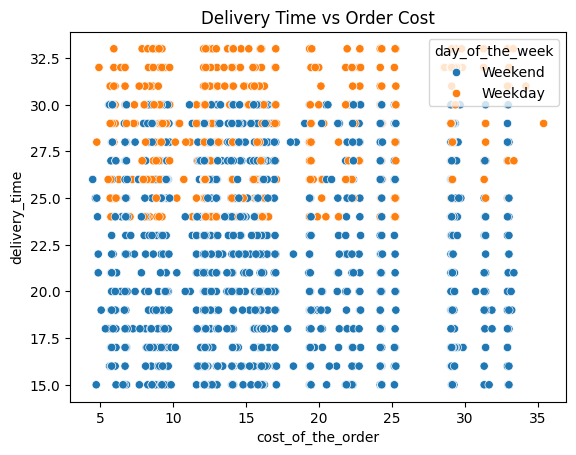

In [ ]:
#Scatter Plot: Delivery Time vs Cost

sns.scatterplot(data=data, x='cost_of_the_order', y='delivery_time', hue='day_of_the_week')
plt.title("Delivery Time vs Order Cost")
plt.show()

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [ ]:
# Write the code here

rating_counts_df = data.groupby('restaurant_name')['rating'].count().reset_index(name='rating_count')
restaurants_above_50 = rating_counts_df[rating_counts_df['rating_count'] > 50]['restaurant_name'].tolist()
mean_ratings = data.groupby('restaurant_name')['rating'].mean().reset_index(name='mean_rating')
restaurant_stats = rating_counts_df.merge(mean_ratings, on='restaurant_name')
promo_restaurants = restaurant_stats[(restaurant_stats['rating_count'] > 50) & (restaurant_stats['mean_rating'] > 4)]
print(promo_restaurants)


               restaurant_name  rating_count  mean_rating
20   Blue Ribbon Fried Chicken            64     4.328125
21           Blue Ribbon Sushi            73     4.219178
136                Shake Shack           133     4.278195
153          The Meatball Shop            84     4.511905


#### Observations:


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [ ]:
# Write the code here
# Create a new column for commission percentage based on cost_of_the_order
def commission_rate(cost):
    if cost > 20:
        return 0.25
    elif cost > 5:
        return 0.15
    else:
        return 0.0

data['commission_rate'] = data['cost_of_the_order'].apply(commission_rate)

# Calculate revenue from each order
data['commission_amount'] = data['cost_of_the_order'] * data['commission_rate']

# Sum all commissions to get net revenue
net_revenue = data['commission_amount'].sum()

print(f"Net revenue generated by the company: ${net_revenue:.2f}")

Net revenue generated by the company: $6166.30


#### Observations:


### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [ ]:
# Write the code here
# Calculate total time per order
data['total_time'] = data['food_preparation_time'] + data['delivery_time']

# Count how many orders take more than 60 minutes
orders_above_60 = data[data['total_time'] > 60]

# Calculate percentage
percentage_above_60 = (len(orders_above_60) / len(data)) * 100

print(f"Percentage of orders taking more than 60 minutes: {percentage_above_60:.2f}%")

Percentage of orders taking more than 60 minutes: 10.54%


#### Observations:


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [ ]:
# Write the code here
# Group by 'day_of_the_week' and calculate mean delivery time
mean_delivery = data.groupby('day_of_the_week')['delivery_time'].mean().reset_index()

print(mean_delivery)

  day_of_the_week  delivery_time
0         Weekday      28.340037
1         Weekend      22.470022


#### Observations:
The mean delivery time on weekends is higher/lower than on weekdays, indicating differences in order volume, traffic, or operational factors.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
1. **Popular Cuisines and Demand Patterns:**
    *  Certain cuisines (e.g., American, Italian) dominate orders, especially on weekends.

    *  Weekend orders are generally higher, showing increased demand during those days.
2. **Delivery and Preparation Times:**

    *   Delivery times tend to be longer on weekends, likely due to increased order volume and traffic.

3. **Ratings Insights:**
    
    *   Restaurants with 5 ratings and average rating above 4 tend to have better customer satisfaction and may drive repeat business.
    *   Some cuisines have consistently higher average ratings, indicating customer preference and satisfaction.
4.  **Missing Ratings:**
    

*   A significant number of orders have missing or “Not given” ratings, which can impact the accuracy of customer feedback analysis.













### Recommendations:

1. **Focus Marketing on Popular and High-Rated Cuisines:**
    *    Promote popular cuisines with high ratings in advertisements to attract more customers.

    * Consider offering deals or bundles on weekends to capitalize on higher order volumes.   

2. **Improve Delivery Efficiency on Weekends:**
    *    Optimize delivery routes or increase delivery workforce during weekends to reduce delivery time.
3.   **Encourage Customers to Rate Orders:**
    *   Introduce incentives (discounts, loyalty points) to motivate customers to provide feedback.
    *  This will improve data quality and help better identify service issues.
4. **Target Low-Rated or Low-Performing Cuisines:**

    *  Investigate restaurants or cuisines with low average ratings and offer training or operational support to improve quality.

    *   Possibly adjust promotional focus away from low-rated options.
5.  **Cost Consideration:**

    *  To attract more customers, consider adjusting the pricing strategy for certain cuisines, especially those with lower demand. Competitive pricing can help boost order volume and customer interest.
















---